# Deliver Death (Mercenary)

Deliver Death is a melee finisher on a 45 s cooldown. It hits an adjacent enemy for a multiple
of the Mercenary's **weapon value**. The multiplier is much larger when the target is below 25%
HP. There is no hit roll and no dodge, so only armor and the target's HP threshold matter.

| | |
|---|---|
| Class | Mercenary |
| Target | Selected enemy; must be adjacent (including diagonals) |
| Cost | 75 endurance |
| Cooldown | 45 s (`add_skill_cooldown`), started even when the blow glances off |
| Landing roll | none: no melee hit table, no dodge |
| Damage | `do_hurt(dam, 0)`: melee damage, reduced by armor, at ¼ HP per point |
| Source | `server/src/driver/skill/mercenary.rs::skill_deliver_death`, `weapon_skill_scale_pct` |

---

# Formula

With the caster's weapon value $W = \max(1, \text{weapon})$ and the target's HP fraction
$h = \lfloor a\_hp / \text{max\_hp} \rfloor$ in permille:

$$
\text{base} = \begin{cases}
15W + \text{rand}(6W) & h < 250 \quad\text{(execute)}\\
6W + \text{rand}(3W) & \text{otherwise}
\end{cases}
\qquad
\text{scale} = \operatorname{clamp}\!\left(50 + \lfloor p/2 \rfloor,\ 50,\ 150\right)\%
$$

$$
\text{dam} = \left\lfloor \text{base}\cdot\text{scale}/100 \right\rfloor
\qquad
\text{HP removed} = \max(0,\ \text{dam} - \text{armor}) / 4
$$

The skill does **not** go through immunity or the race modifier. It only sets the scale, which is
linear from 50% at skill 0 to 150% at skill 200.

| Quantity | Breakpoint |
|---|---|
| Scale floor / ceiling | 50% at $p = 0$; 150% at $p \ge 200$ |
| Scale at the raise caps | 102% at 105, 110% at 120 |
| Execute threshold | target below 25.0% HP (permille, truncated) |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
COOLDOWN_S = 45
END_COST = 75

# Model

In [2]:
def scale_pct(p):
    """`weapon_skill_scale_pct`."""
    return mm.clamp(50 + mm.idiv(p, 2), 50, 150)


def dd_rolls(weapon, p, execute):
    """All equally likely `dam` values (before armor) for one cast."""
    w = max(1, weapon)
    lo, n = (15 * w, 6 * w) if execute else (6 * w, 3 * w)
    base = lo + np.arange(n)
    return mm.idiv(base * scale_pct(p), 100)


def dd_expected_hp(weapon, p, execute, armor=0):
    p = np.atleast_1d(p)
    out = np.array([np.mean(mm.hurt_hp(dd_rolls(weapon, int(x), execute), armor)) for x in p])
    return mm._scalar(out if out.size > 1 else out[0])


def dd_min_hp(weapon, p, execute, armor=0):
    p = np.atleast_1d(p)
    out = np.array([mm.hurt_hp(dd_rolls(weapon, int(x), execute).min(), armor) for x in p])
    return mm._scalar(out if out.size > 1 else out[0])


def swing_expected_hp(weapon, strength, armor=0):
    """A normal landed melee hit at Δ = 0 (no table bonus), for comparison."""
    return np.mean(mm.hurt_hp(mm.melee_raw_rolls(weapon, strength), armor))

# Validation

- `weapon_skill_scale_ramps_from_half_to_one_and_a_half`: 0 → 50, 100 → 100, 200 → 150,
  400 → 150.
- `deliver_death_requires_endurance`: `a_end` 74,999 is refused (75 endurance = 75,000).
- `deliver_death_is_blocked_while_recharging`: no endurance is spent during the cooldown.

In [3]:
assert scale_pct(0) == 50 and scale_pct(100) == 100 and scale_pct(200) == 150 and scale_pct(400) == 150
assert 74_999 < END_COST * 1000
assert scale_pct(105) == 102 and scale_pct(120) == 110

# Execute at W 40, skill 120: base 600..839, x1.10.
r = dd_rolls(40, 120, True)
assert r.min() == 660 and r.max() == 922 and len(r) == 240
assert dd_expected_hp(40, 120, True) == 197.75
print("Deliver Death model OK")

Deliver Death model OK


# Plots

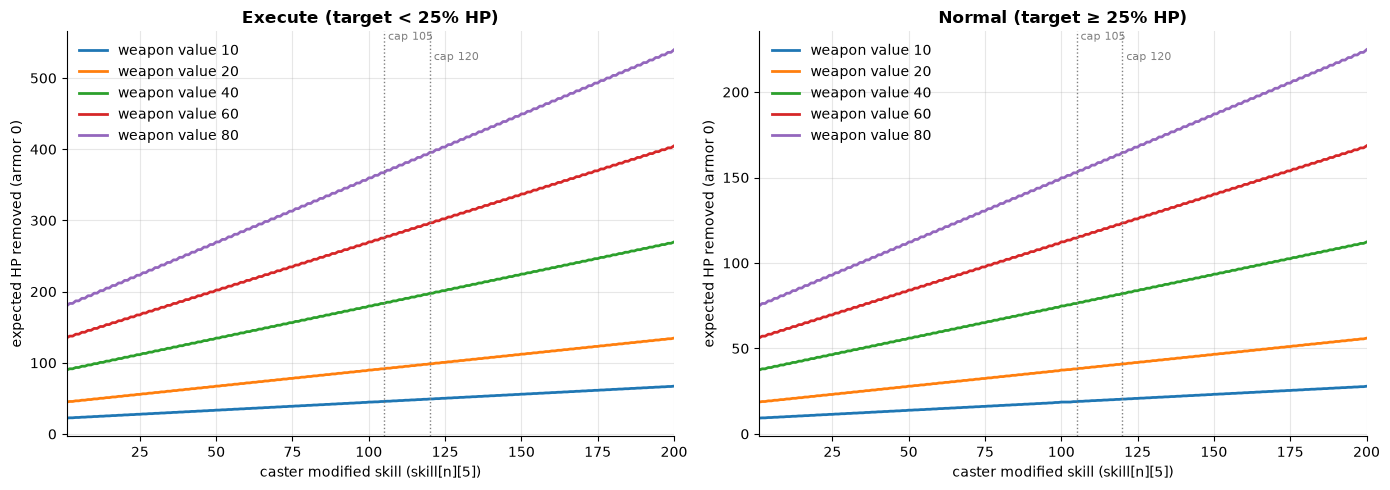

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, execute, title in ((axes[0], True, "Execute (target < 25% HP)"),
                           (axes[1], False, "Normal (target ≥ 25% HP)")):
    for wv in mm.WV_SWEEP:
        ax.plot(P, dd_expected_hp(wv, P, execute), label=f"weapon value {wv}")
    mm.skill_axis(ax, "expected HP removed (armor 0)", title)
    mm.mark_caps(ax)
    ax.legend()
plt.tight_layout()

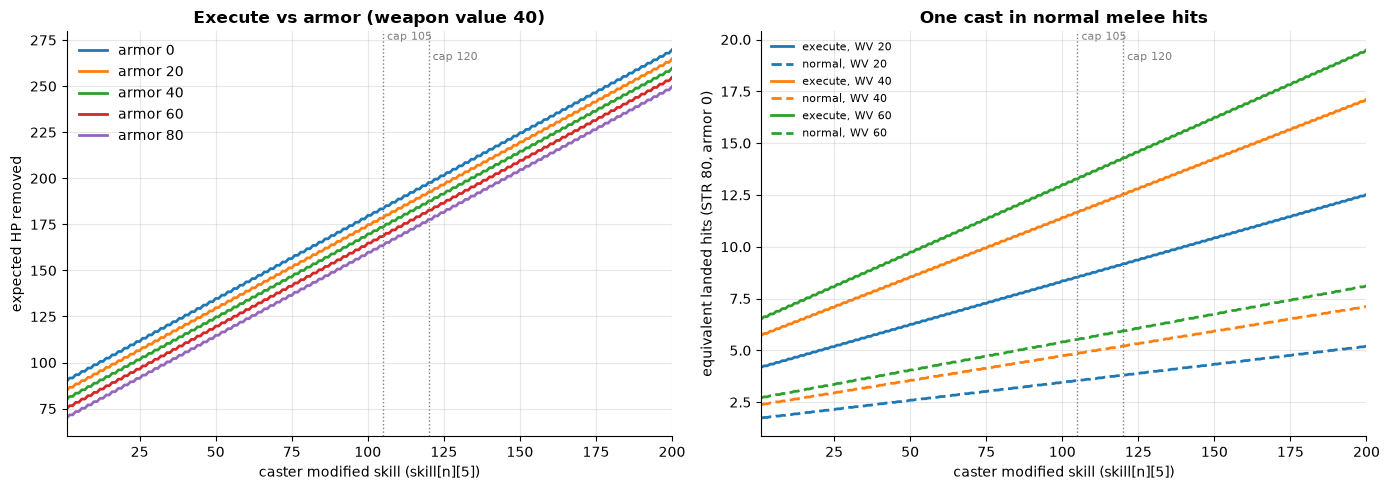

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for armor in mm.ARMOR_SWEEP:
    ax.plot(P, dd_expected_hp(40, P, True, armor), label=f"armor {armor}")
mm.skill_axis(ax, "expected HP removed", "Execute vs armor (weapon value 40)")
mm.mark_caps(ax)
ax.legend()

# Execute damage measured in normal landed hits of the same weapon.
ax = axes[1]
for wv in (20, 40, 60):
    swing = swing_expected_hp(wv, 80)
    line, = ax.plot(P, dd_expected_hp(wv, P, True) / swing, label=f"execute, WV {wv}")
    ax.plot(P, dd_expected_hp(wv, P, False) / swing, color=line.get_color(), ls="--", label=f"normal, WV {wv}")
mm.skill_axis(ax, "equivalent landed hits (STR 80, armor 0)", "One cast in normal melee hits")
mm.mark_caps(ax)
ax.legend(fontsize=8)
plt.tight_layout()

Measured in swings, Deliver Death favours high weapon value. The finisher scales only with WV,
while a swing also carries the flat `rand(6) + rand(STR/2)` term. At skill 120 an execute is worth
9.2 hits with WV 20 and 14.3 hits with WV 60 (STR 80).

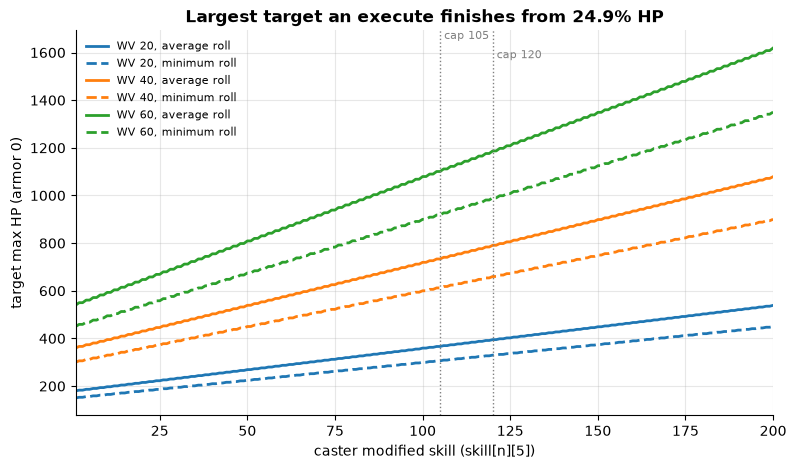

In [6]:
# Largest max HP an execute is guaranteed / expected to kill from just under 25% HP.
fig, ax = plt.subplots()
for wv in (20, 40, 60):
    line, = ax.plot(P, 4 * dd_expected_hp(wv, P, True), label=f"WV {wv}, average roll")
    ax.plot(P, 4 * dd_min_hp(wv, P, True), color=line.get_color(), ls="--", label=f"WV {wv}, minimum roll")
mm.skill_axis(ax, "target max HP (armor 0)", "Largest target an execute finishes from 24.9% HP")
mm.mark_caps(ax)
ax.legend(fontsize=8)

# Observations

- **A strong execute at almost no cost.** With weapon value 40 at skill 120, an execute removes
  198 HP on average (armor 0), the same as 12.6 normal landed hits with STR 80. Every roll removes
  at least 165 HP. On average it finishes any target with up to about 790 max HP from just
  under 25% (660 guaranteed). With no hit roll and no dodge, it is the most reliable melee damage
  the Mercenary has.
- **The non-execute branch is still worth casting.** Above 25% HP the same character deals 82 HP,
  about 5 hits' worth. The cooldown is the same, so the best play is to hold it for the execute.
  Casting it early still beats letting it sit unused for a whole fight.
- **Over a 45 s cooldown it adds roughly +10% to +25% melee DPS.** At 2 swings/s and 60% to hit,
  a Mercenary lands about 54 hits per 45 s. One execute adds 12.6 more (+23%), one normal cast
  5.2 (+10%). Across WV 20–60 and skill 105–200, an execute is worth 8.5 to
  19.5 hits.
- **Skill matters less than weapon value.** The scale only runs from 102% at skill 105 to 110% at
  120, and reaches 150% only at skill 200. Going from 105 to 120 adds 8% damage. Going from
  WV 40 to 60 adds 50%. Immunity and race are ignored.
- **Armor is a small, flat tax.** The finisher hits in one big chunk, so armor is subtracted once:
  armor 40 lowers the WV-40 skill-120 execute from 198 to 188 HP (−5%), and the normal branch
  from 82 to 72 HP (−12%).
- **Endurance is spent and the cooldown starts even when the blow glances off.** On a
  high-armor target the cast can do 0 damage and still cost 75 endurance and 45 s.